# Data loading

In [ ]:
#!/bin/bash
!#!/bin/bash
!kaggle datasets download awsaf49/brats2020-training-data

Dataset URL: https://www.kaggle.com/datasets/awsaf49/brats2020-training-data
License(s): CC0-1.0
100% 6.74G/6.76G [00:33<00:00, 175MB/s]
100% 6.76G/6.76G [00:33<00:00, 214MB/s]


In [ ]:
!unzip /content/brats2020-training-data.zip -d datasets/

Streaming output truncated to the last 5000 lines.
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_63.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_64.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_65.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_66.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_67.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_68.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_69.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_7.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_70.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_71.h5  
  inflating: datasets/BraTS2020_training_data/content/data/volume_70_slice_72.h5  
  inflating: datasets/BraTS2020_train

In [ ]:
import pandas as pd
import h5py
import numpy as np
import os
from sklearn.model_selection import train_test_split

# Define paths
metadata_path = "datasets/BraTS2020_training_data/content/data/meta_data.csv"
base_dir = "datasets/BraTS2020_training_data/content/data"  # Base directory for images

# Load metadata
metadata = pd.read_csv(metadata_path)

# Load only 2000 images
def load_limited_data(metadata, base_dir, limit=2000):
    data = []
    labels = []
    count = 0

    for i, row in metadata.iterrows():
        if count >= limit:
            break

        # Construct full path
        slice_path = os.path.join(base_dir, os.path.basename(row['slice_path'].strip()))
        label = row['target']  # Target column as label

        try:
            with h5py.File(slice_path, "r") as f:
                # Check available keys inside the file
                print(f"Keys in {slice_path}:", list(f.keys()))

                # Replace "image" with the actual key found in the file
                image = np.array(f["image"])

                data.append(image)
                labels.append(label)
                count += 1

        except Exception as e:
            print(f"Error loading file {slice_path}: {e}")

    return np.array(data), np.array(labels)

# Load first 2000 slices
images, labels = load_limited_data(metadata, base_dir, limit=2000)

# Split into train, validation, and test sets
X_train, X_temp, y_train, y_temp = train_test_split(images, labels, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print(f"Train: {X_train.shape}, Validation: {X_val.shape}, Test: {X_test.shape}")
print(f"Unique Train Labels: {np.unique(y_train)}")


Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_0.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_1.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_2.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_3.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_4.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_5.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_6.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_7.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_8.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume_41_slice_9.h5: ['image', 'mask']
Keys in datasets/BraTS2020_training_data/content/data/volume

In [ ]:
import pandas as pd

# Paths
metadata_path = "datasets/BraTS2020_training_data/content/data/meta_data.csv"
mapping_path = "datasets/BraTS2020_training_data/content/data/name_mapping.csv"

# Load metadata and name mapping
metadata = pd.read_csv(metadata_path)
name_mapping = pd.read_csv(mapping_path)

# Check columns
print("Meta Data Columns:", metadata.columns)
print("Name Mapping Columns:", name_mapping.columns)

# Preview first few rows
print(metadata.head())
print(name_mapping.head())


Meta Data Columns: Index(['slice_path', 'target', 'volume', 'slice'], dtype='object')
Name Mapping Columns: Index(['Grade', 'BraTS_2017_subject_ID', 'BraTS_2018_subject_ID',
       'TCGA_TCIA_subject_ID', 'BraTS_2019_subject_ID',
       'BraTS_2020_subject_ID'],
      dtype='object')
                           slice_path  target  volume  slice
0  /content/data/volume_41_slice_0.h5       0      41      0
1  /content/data/volume_41_slice_1.h5       0      41      1
2  /content/data/volume_41_slice_2.h5       0      41      2
3  /content/data/volume_41_slice_3.h5       0      41      3
4  /content/data/volume_41_slice_4.h5       0      41      4
  Grade BraTS_2017_subject_ID BraTS_2018_subject_ID TCGA_TCIA_subject_ID  \
0   HGG   Brats17_CBICA_AAB_1   Brats18_CBICA_AAB_1                  NaN   
1   HGG   Brats17_CBICA_AAG_1   Brats18_CBICA_AAG_1                  NaN   
2   HGG   Brats17_CBICA_AAL_1   Brats18_CBICA_AAL_1                  NaN   
3   HGG   Brats17_CBICA_AAP_1   Brats18_CBICA

In [ ]:
# Convert volume to match BraTS_2020_subject_ID format
metadata["volume"] = metadata["volume"].astype(int).apply(lambda x: f"BraTS20_Training_{x:03d}")

# Strip any extra spaces in the name mapping
name_mapping["BraTS_2020_subject_ID"] = name_mapping["BraTS_2020_subject_ID"].str.strip()

# Merge datasets
merged_data = metadata.merge(name_mapping, left_on="volume", right_on="BraTS_2020_subject_ID", how="left")

# Check unique tumor types
print("Unique Tumor Types:", merged_data["Grade"].unique())

# Display a sample of merged data
print(merged_data.head())


Unique Tumor Types: ['HGG' 'LGG']
                           slice_path  target                volume  slice  \
0  /content/data/volume_41_slice_0.h5       0  BraTS20_Training_041      0   
1  /content/data/volume_41_slice_1.h5       0  BraTS20_Training_041      1   
2  /content/data/volume_41_slice_2.h5       0  BraTS20_Training_041      2   
3  /content/data/volume_41_slice_3.h5       0  BraTS20_Training_041      3   
4  /content/data/volume_41_slice_4.h5       0  BraTS20_Training_041      4   

  Grade BraTS_2017_subject_ID BraTS_2018_subject_ID TCGA_TCIA_subject_ID  \
0   HGG   Brats17_CBICA_AQZ_1   Brats18_CBICA_AQZ_1                  NaN   
1   HGG   Brats17_CBICA_AQZ_1   Brats18_CBICA_AQZ_1                  NaN   
2   HGG   Brats17_CBICA_AQZ_1   Brats18_CBICA_AQZ_1                  NaN   
3   HGG   Brats17_CBICA_AQZ_1   Brats18_CBICA_AQZ_1                  NaN   
4   HGG   Brats17_CBICA_AQZ_1   Brats18_CBICA_AQZ_1                  NaN   

  BraTS_2019_subject_ID BraTS_2020_subje

In [ ]:
print("Meta Data - Volume Column Sample:", metadata["volume"].head())
print("Name Mapping - BraTS_2020_subject_ID Sample:", name_mapping["BraTS_2020_subject_ID"].head())

print("Meta Data - Volume Type:", metadata["volume"].dtype)
print("Name Mapping - Subject ID Type:", name_mapping["BraTS_2020_subject_ID"].dtype)


Meta Data - Volume Column Sample: 0    BraTS20_Training_041
1    BraTS20_Training_041
2    BraTS20_Training_041
3    BraTS20_Training_041
4    BraTS20_Training_041
Name: volume, dtype: object
Name Mapping - BraTS_2020_subject_ID Sample: 0    BraTS20_Training_001
1    BraTS20_Training_002
2    BraTS20_Training_003
3    BraTS20_Training_004
4    BraTS20_Training_005
Name: BraTS_2020_subject_ID, dtype: object
Meta Data - Volume Type: object
Name Mapping - Subject ID Type: object


In [ ]:
# Map tumor types to numerical labels
tumor_type_mapping = {"HGG": 0, "LGG": 1}  # Modify if more types exist
merged_data["tumor_class"] = merged_data["Grade"].map(tumor_type_mapping)


In [ ]:
import h5py
import numpy as np
import os

# Define base directory
base_dir = "datasets/BraTS2020_training_data/content/data"

# Load images and masks
def load_images_and_masks(metadata, base_dir, limit=2000):
    images = []
    masks = []
    labels = []
    count = 0

    for i, row in metadata.iterrows():
        if count >= limit:
            break

        # Construct full path
        slice_path = os.path.join(base_dir, os.path.basename(row['slice_path'].strip()))
        label = row["tumor_class"]  # Use tumor type as label

        try:
            with h5py.File(slice_path, "r") as f:
                image = np.array(f["image"])  # Extract MRI scan
                mask = np.array(f["mask"])   # Extract segmentation mask
                images.append(image)
                masks.append(mask)
                labels.append(label)
                count += 1
        except Exception as e:
            print(f"Error loading file {slice_path}: {e}")

    return np.array(images), np.array(masks), np.array(labels)

# Load first 2000 slices
images, masks, labels = load_images_and_masks(merged_data, base_dir, limit=2000)

# Split into train, validation, and test sets
X_train, X_temp, y_train_masks, y_temp_masks = train_test_split(images, masks, test_size=0.3, random_state=42)
X_val, X_test, y_val_masks, y_test_masks = train_test_split(X_temp, y_temp_masks, test_size=0.5, random_state=42)

print(f"Train Images: {X_train.shape}, Train Masks: {y_train_masks.shape}")
print(f"Validation Images: {X_val.shape}, Validation Masks: {y_val_masks.shape}")
print(f"Test Images: {X_test.shape}, Test Masks: {y_test_masks.shape}")


Train Images: (1400, 240, 240, 4), Train Masks: (1400, 240, 240, 3)
Validation Images: (300, 240, 240, 4), Validation Masks: (300, 240, 240, 3)
Test Images: (300, 240, 240, 4), Test Masks: (300, 240, 240, 3)


In [ ]:
import os
import h5py
import numpy as np

base_dir = "datasets/BraTS2020_training_data/content/data"
tumor_slices = 0
total_slices = 0
tumor_files = []  # List to store filenames that have tumors

# Get only the first 100 `.h5` files
h5_files = sorted([f for f in os.listdir(base_dir) if f.endswith(".h5")])[:100]

# Scan these files
for file_name in h5_files:
    file_path = os.path.join(base_dir, file_name)

    with h5py.File(file_path, "r") as f:
        mask = np.array(f["mask"])  # Ensure correct key

    total_slices += 1
    if np.max(mask) > 0:  # If mask contains a tumor
        tumor_slices += 1
        tumor_files.append(file_name)  # Store file name

# Print results
print(f"Scanned MRI Slices: {total_slices} / 100")
print(f"Tumor-Containing Slices: {tumor_slices}")

# Show first few tumor-containing files (if any)
if tumor_files:
    print("Examples of tumor-containing slices:", tumor_files[:10])  # Show first 10 slices
else:
    print("⚠️ No tumor-containing slices found in the first 100 files!")


Scanned MRI Slices: 100 / 100
Tumor-Containing Slices: 19
Examples of tumor-containing slices: ['volume_100_slice_100.h5', 'volume_100_slice_101.h5', 'volume_100_slice_102.h5', 'volume_100_slice_103.h5', 'volume_100_slice_104.h5', 'volume_100_slice_105.h5', 'volume_100_slice_106.h5', 'volume_100_slice_107.h5', 'volume_100_slice_108.h5', 'volume_100_slice_109.h5']


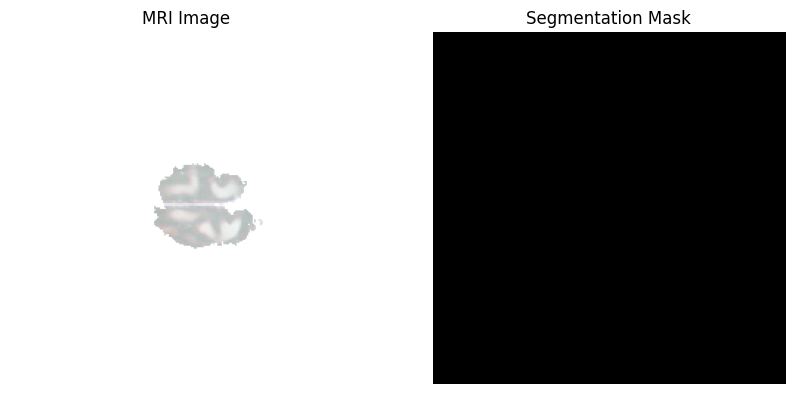

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import os

# Load a single image and mask from an h5 file
def load_image_and_mask(slice_path):
    with h5py.File(slice_path, "r") as f:
        image = np.array(f["image"])  # Replace "image" if needed
        mask = np.array(f["mask"])   # Replace "mask" if needed
    return image, mask

# Load one example file
base_dir = "datasets/BraTS2020_training_data/content/data"
example_file = os.path.join(base_dir, "volume_28_slice_134.h5")  # Change this if needed
image, mask = load_image_and_mask(example_file)

# Fix normalization issues
image = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-7)  # Normalize to [0,1]

# Enhance mask visualization
if np.max(mask) == 0:
    print("WARNING: Mask contains only zeros (no tumor in this slice).")
else:
    mask = mask / np.max(mask)  # Normalize mask if needed

# Display the image and mask
plt.figure(figsize=(10, 5))

# Show MRI image
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("MRI Image")
plt.axis("off")

# Show Mask (force a colormap for visibility)
plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="jet")  # Use jet colormap for better contrast
plt.title("Segmentation Mask")
plt.axis("off")

plt.show()


In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import os

# Load only tumor-containing slices
def load_tumor_slices(base_dir, tumor_files):
    images = []
    masks = []

    for file_name in tumor_files:
        file_path = os.path.join(base_dir, file_name)

        with h5py.File(file_path, "r") as f:
            image = np.array(f["image"])
            mask = np.array(f["mask"])

        images.append(image)
        masks.append(mask)

    return np.array(images), np.array(masks)

# Load tumor slices
images, masks = load_tumor_slices(base_dir, tumor_files)

print(f"Loaded {len(images)} tumor-containing slices.")


Loaded 19 tumor-containing slices.


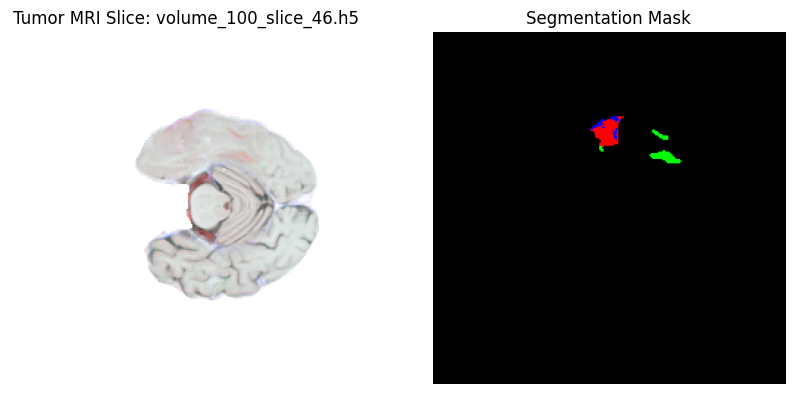

In [ ]:
# Pick any tumor slice to display
index =15   # Change this if you want to see another slice

# Normalize image for display
image = images[index]
image = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-7)

# Normalize mask if needed
mask = masks[index]
mask = mask / np.max(mask) if np.max(mask) > 0 else mask

# Plot the MRI image and mask
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title(f"Tumor MRI Slice: {tumor_files[index]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="jet")  # Jet colormap for visibility
plt.title("Segmentation Mask")
plt.axis("off")

plt.show()


# Find out it has Empty masks so fixted it here

In [ ]:
import os
import h5py
import numpy as np

base_dir = "datasets/BraTS2020_training_data/content/data"

# Function to filter and load only tumor slices
def load_tumor_slices(base_dir, limit=2000):
    images = []
    masks = []
    tumor_files = []
    count = 0

    # Loop through dataset and filter tumor slices
    for file_name in sorted(os.listdir(base_dir)):
        if count >= limit:
            break
        if file_name.endswith(".h5"):
            file_path = os.path.join(base_dir, file_name)

            with h5py.File(file_path, "r") as f:
                image = np.array(f["image"])
                mask = np.array(f["mask"])

            # Only keep slices where mask has tumor pixels
            if np.max(mask) > 0:
                images.append(image)
                masks.append(mask)
                tumor_files.append(file_name)
                count += 1

    return np.array(images), np.array(masks), tumor_files

# Load filtered dataset (only slices with tumors)
X_filtered, y_filtered_masks, tumor_file_names = load_tumor_slices(base_dir, limit=2000)

print(f"Filtered Dataset: {X_filtered.shape} Images, {y_filtered_masks.shape} Masks")
print(f"Example Tumor-Containing Files: {tumor_file_names[:10]}")


Filtered Dataset: (2000, 240, 240, 4) Images, (2000, 240, 240, 3) Masks
Example Tumor-Containing Files: ['volume_100_slice_100.h5', 'volume_100_slice_101.h5', 'volume_100_slice_102.h5', 'volume_100_slice_103.h5', 'volume_100_slice_104.h5', 'volume_100_slice_105.h5', 'volume_100_slice_106.h5', 'volume_100_slice_107.h5', 'volume_100_slice_108.h5', 'volume_100_slice_109.h5']


In [ ]:
from sklearn.model_selection import train_test_split

# Split into train, validation, and test
X_train, X_temp, y_train_masks, y_temp_masks = train_test_split(X_filtered, y_filtered_masks, test_size=0.3, random_state=42)
X_val, X_test, y_val_masks, y_test_masks = train_test_split(X_temp, y_temp_masks, test_size=0.5, random_state=42)

print(f"Train Images: {X_train.shape}, Train Masks: {y_train_masks.shape}")
print(f"Validation Images: {X_val.shape}, Validation Masks: {y_val_masks.shape}")
print(f"Test Images: {X_test.shape}, Test Masks: {y_test_masks.shape}")


Train Images: (1400, 240, 240, 4), Train Masks: (1400, 240, 240, 3)
Validation Images: (300, 240, 240, 4), Validation Masks: (300, 240, 240, 3)
Test Images: (300, 240, 240, 4), Test Masks: (300, 240, 240, 3)


In [ ]:
import numpy as np

# Save data and masks
np.save('X_train.npy', X_train)
np.save('y_train_masks.npy', y_train_masks)
np.save('X_val.npy', X_val)
np.save('y_val_masks.npy', y_val_masks)
np.save('X_test.npy', X_test)
np.save('y_test_masks.npy', y_test_masks)

print("Datasets saved successfully!")


Datasets saved successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Move files to Google Drive
!mkdir /content/drive/MyDrive/datasets/
!mv *.npy /content/drive/MyDrive/datasets/
print("Datasets moved to Google Drive!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
mkdir: cannot create directory ‘/content/drive/MyDrive/datasets/’: File exists
Datasets moved to Google Drive!


In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
# Load files from Google Drive
X_train = np.load('/content/drive/MyDrive/datasets/X_train.npy')
y_train_masks = np.load('/content/drive/MyDrive/datasets/y_train_masks.npy')
X_val = np.load('/content/drive/MyDrive/datasets/X_val.npy')
y_val_masks = np.load('/content/drive/MyDrive/datasets/y_val_masks.npy')
X_test = np.load('/content/drive/MyDrive/datasets/X_test.npy')
y_test_masks = np.load('/content/drive/MyDrive/datasets/y_test_masks.npy')

print("Datasets loaded successfully from Google Drive!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Datasets loaded successfully from Google Drive!


In [3]:
print(f"Train Images: {X_train.shape}, Train Masks: {y_train_masks.shape}")
print(f"Validation Images: {X_val.shape}, Validation Masks: {y_val_masks.shape}")
print(f"Test Images: {X_test.shape}, Test Masks: {y_test_masks.shape}")

Train Images: (1400, 240, 240, 4), Train Masks: (1400, 240, 240, 3)
Validation Images: (300, 240, 240, 4), Validation Masks: (300, 240, 240, 3)
Test Images: (300, 240, 240, 4), Test Masks: (300, 240, 240, 3)


# MOdel building, Segnet+ monai Unet(ensemble)

In [ ]:
!pip install monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 21.4 MB/s eta 0:00:00


In [6]:
import torch
import torch.nn as nn

import torch.nn as nn

class SegNet(nn.Module):
    def __init__(self, in_channels=4, out_channels=1):
        super(SegNet, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2, return_indices=False),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2, return_indices=False),
        )
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=True),
            nn.Conv2d(64, out_channels, kernel_size=3, padding=1),
         #   nn.Sigmoid(),
        )

    def forward(self, x):
        # Encoder
        for layer in self.encoder:
            x = layer(x)
            #print(f"Encoder Output Size: {x.size()}")  # Debug encoder output sizes

        # Decoder
        for layer in self.decoder:
            x = layer(x)
        #    print(f"Decoder Output Size: {x.size()}")  # Debug decoder output sizes

        return x


# Initialize SegNet
segnet = SegNet(in_channels=4, out_channels=1).to("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
segnet

SegNet(
  (encoder): Sequential(
    (0): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='bilinear')
    (1): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Upsample(scale_factor=2.0, mode='bilinear')
    (5): Conv2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): Sig

In [7]:
!pip install monai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.2 MB/s eta 0:00:00


In [8]:
from monai.networks.nets import UNet

device = "cuda" if torch.cuda.is_available() else "cpu"
unet = UNet(
    spatial_dims=2,
    in_channels=4,  # 4-channel input
    out_channels=1,
    channels=(16, 32, 64, 128),  # fewer channels
    strides=(2, 2, 2),          # fewer pooling layers
    num_res_units=1,            # reduce complexity
).to(device)

In [ ]:
unet

UNet(
  (model): Sequential(
    (0): ResidualUnit(
      (conv): Sequential(
        (unit0): Convolution(
          (conv): Conv2d(4, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (adn): ADN(
            (N): InstanceNorm2d(16, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
            (D): Dropout(p=0.0, inplace=False)
            (A): PReLU(num_parameters=1)
          )
        )
        (unit1): Convolution(
          (conv): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (adn): ADN(
            (N): InstanceNorm2d(16, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
            (D): Dropout(p=0.0, inplace=False)
            (A): PReLU(num_parameters=1)
          )
        )
      )
      (residual): Conv2d(4, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    )
    (1): SkipConnection(
      (submodule): Sequential(
        (0): ResidualUnit(
          (conv): Sequential(
            (unit

In [ ]:
from torch.utils.data import DataLoader, Dataset
import cv2

def normalize_image(img):
    # simple z-score
    mean = np.mean(img)
    std = np.std(img)
    if std < 1e-5:
        return img  # avoid dividing by zero
    return (img - mean) / std

def resize_and_normalize(img, mask, target_size=(256, 256)):
    # resize
    img_resized = cv2.resize(img, target_size, interpolation=cv2.INTER_LINEAR)
    mask_resized = cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)

    # normalize image
    img_resized = normalize_image(img_resized)

    return img_resized, mask_resized

# Modify Dataset Class to Include Resizing
class MRIDataset(Dataset):
    def __init__(self, images, masks, target_size=(256, 256)):
        self.images = images
        self.masks = masks
        self.target_size = target_size

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img, mask = self.images[idx], self.masks[idx]
        img, mask = resize_and_normalize(img, mask, self.target_size)

        # move channel to front
        img = np.transpose(img, (2, 0, 1))  # (H, W, C) → (C, H, W)
        if mask.ndim == 3:
            mask = mask[..., 0]
        mask = np.expand_dims(mask, axis=0)

        return torch.tensor(img, dtype=torch.float32), torch.tensor(mask, dtype=torch.float32)




# Reload DataLoaders with updated dataset class
train_dataset = MRIDataset(X_train, y_train_masks)
val_dataset = MRIDataset(X_val, y_val_masks)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8)


# # Reload DataLoaders with fixed dataset class
# train_dataset = MRIDataset(X_train, y_train_masks)
# val_dataset = MRIDataset(X_val, y_val_masks)

# train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
# val_loader = DataLoader(val_dataset, batch_size=8)

print(f"Fixed Input Shape: {train_dataset[0][0].shape}")  # Should be (1, 240, 240)


Fixed Input Shape: torch.Size([4, 256, 256])


In [ ]:
y_train_masks = (y_train_masks > 0).astype(np.float32)
y_val_masks = (y_val_masks > 0).astype(np.float32)
y_test_masks = (y_test_masks > 0).astype(np.float32)


In [ ]:
from tqdm import tqdm
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam, lr_scheduler
import torch
import torch.nn as nn

# ✅ Loss function: ComboLoss (Dice + BCE)
class ComboLoss(nn.Module):
    def __init__(self, alpha=0.6):  # 60% Dice, 40% BCE
        super(ComboLoss, self).__init__()
        self.alpha = alpha

    def forward(self, pred, target):
        pred = torch.sigmoid(pred)  # Ensure [0, 1] range
        intersection = (pred * target).sum()
        dice = 1 - (2 * intersection + 1) / (pred.sum() + target.sum() + 1)
        bce = F.binary_cross_entropy(pred, target)
        return self.alpha * dice + (1 - self.alpha) * bce

# ✅ Dice Score Calculation
def compute_dice(pred, target):
    pred = (torch.sigmoid(pred) > 0.5).float()
    intersection = (pred * target).sum()
    return (2.0 * intersection) / (pred.sum() + target.sum() + 1e-6)

# ✅ Initialize loss function
loss_function = ComboLoss(alpha=0.6)

# ✅ Optimizers with adjusted learning rate
segnet_optimizer = Adam(segnet.parameters(), lr=1e-4)
unet_optimizer = Adam(unet.parameters(), lr=1e-4)

# ✅ Learning Rate Schedulers
segnet_scheduler = lr_scheduler.ReduceLROnPlateau(segnet_optimizer, mode='min', factor=0.1, patience=5, verbose=True)
unet_scheduler = lr_scheduler.ReduceLROnPlateau(unet_optimizer, mode='min', factor=0.1, patience=5, verbose=True)

# ✅ Training loop
device = "cuda" if torch.cuda.is_available() else "cpu"
num_epochs = 50
grad_clip = 1.0  # Gradient clipping to prevent explosion
best_val_loss = float('inf')  # Track best validation loss for early stopping and checkpointing

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch + 1}/{num_epochs}")

    for model, optimizer, scheduler, name in [
        (segnet, segnet_optimizer, segnet_scheduler, "SegNet"),
        (unet, unet_optimizer, unet_scheduler, "U-Net")
    ]:
        model.train()
        epoch_loss = 0
        epoch_dice = 0

        # Training Phase
        with tqdm(train_loader, desc=f"Training {name}", unit="batch") as t:
            for batch in t:
                imgs, masks = batch[0].to(device), batch[1].to(device)
                optimizer.zero_grad()

                outputs = model(imgs)
                loss = loss_function(outputs, masks)
                loss.backward()

                # Gradient clipping to avoid gradient explosion
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=grad_clip)

                optimizer.step()
                epoch_loss += loss.item()
                epoch_dice += compute_dice(outputs, masks).item()

                t.set_postfix(loss=loss.item(), dice=compute_dice(outputs, masks).item())

        # Calculate average loss and dice for the epoch
        avg_train_loss = epoch_loss / len(train_loader)
        avg_train_dice = epoch_dice / len(train_loader)
        print(f"{name} Epoch {epoch + 1}/{num_epochs}, Train Loss: {avg_train_loss:.4f}, Train Dice: {avg_train_dice:.4f}")

        # Validation Phase
        model.eval()
        val_loss = 0
        val_dice = 0
        with torch.no_grad():
            for batch in val_loader:
                imgs, masks = batch[0].to(device), batch[1].to(device)
                outputs = model(imgs)
                loss = loss_function(outputs, masks)
                val_loss += loss.item()
                val_dice += compute_dice(outputs, masks).item()

        # Calculate average validation loss and dice
        avg_val_loss = val_loss / len(val_loader)
        avg_val_dice = val_dice / len(val_loader)
        print(f"{name} Epoch {epoch + 1}/{num_epochs}, Val Loss: {avg_val_loss:.4f}, Val Dice: {avg_val_dice:.4f}")

        # Step the learning rate scheduler
        scheduler.step(avg_val_loss)

        # Early Stopping and Model Checkpointing
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            torch.save(model.state_dict(), f"best_{name.lower()}_model.pth")
            print(f"Saved best {name} model with Val Loss: {best_val_loss:.4f}")

        # Early Stopping
        if avg_val_loss < 0.001:  # Stop if validation loss is very low
            print(f"Early stopping for {name} at epoch {epoch + 1}")
            break


Epoch 1/50


Training SegNet: 100%|██████████| 175/175 [00:14<00:00, 12.03batch/s, dice=0.885, loss=0.0728]


SegNet Epoch 1/50, Train Loss: 0.0777, Train Dice: 0.8778
SegNet Epoch 1/50, Val Loss: 0.0997, Val Dice: 0.8422
Saved best SegNet model with Val Loss: 0.0997


Training U-Net: 100%|██████████| 175/175 [00:08<00:00, 20.81batch/s, dice=0.807, loss=0.46]


U-Net Epoch 1/50, Train Loss: 0.2315, Train Dice: 0.9120
U-Net Epoch 1/50, Val Loss: 0.2290, Val Dice: 0.8752

Epoch 2/50


...

U-Net Epoch 49/50, Train Loss: 0.0409, Train Dice: 0.9429
U-Net Epoch 49/50, Val Loss: 0.0809, Val Dice: 0.8764

Epoch 50/50


Training SegNet: 100%|██████████| 175/175 [00:14<00:00, 11.92batch/s, dice=0.489, loss=0.315]


SegNet Epoch 50/50, Train Loss: 0.0714, Train Dice: 0.8847
SegNet Epoch 50/50, Val Loss: 0.0979, Val Dice: 0.8449


Training U-Net: 100%|██████████| 175/175 [00:08<00:00, 21.24batch/s, dice=0.97, loss=0.0215]


U-Net Epoch 50/50, Train Loss: 0.0379, Train Dice: 0.9479
U-Net Epoch 50/50, Val Loss: 0.0806, Val Dice: 0.8758


In [ ]:
# After all training is done
torch.save(unet.state_dict(), "unet_final.pth")

In [ ]:
import numpy as np

segnet.eval()
unet.eval()

def ensemble_predictions(images):
    segnet_preds = []
    unet_preds = []

    with torch.no_grad():
        for img in images:
            # Ensure the image has the correct shape: [1, Channels, Height, Width]
            img_tensor = torch.tensor(img, dtype=torch.float32).unsqueeze(0).to(device)  # [1, Height, Width, Channels]
            img_tensor = img_tensor.permute(0, 3, 1, 2)  # Change it to [1, Channels, Height, Width]

            # Get predictions from both models
            segnet_pred = segnet(img_tensor).cpu().numpy()
            unet_pred = unet(img_tensor).cpu().numpy()

            segnet_preds.append(segnet_pred)
            unet_preds.append(unet_pred)

    # Average the predictions
    ensemble_preds = (np.array(segnet_preds) + np.array(unet_preds)) / 2
    return ensemble_preds

# Ensemble predictions on validation set
ensemble_val_preds = ensemble_predictions(X_val)


In [ ]:
ensemble_val_preds

array([[[[[-17.105068, -23.206356, -22.442463, ..., -19.546156,
           -21.026356, -15.83339 ],
          [-21.595846, -28.888435, -28.290075, ..., -26.586636,
           -28.912647, -21.933594],
          [-18.815432, -24.290913, -23.681566, ..., -22.358835,
           -24.585648, -19.23706 ],
          ...,
          [-20.227232, -26.79436 , -25.761488, ..., -21.371538,
           -22.963991, -17.332842],
          [-22.15183 , -30.57848 , -29.814487, ..., -25.957336,
           -28.03257 , -20.777718],
          [-15.792957, -21.926983, -21.607895, ..., -19.413322,
           -21.12302 , -15.855726]]]],



       [[[[-17.275253, -23.477795, -22.128942, ..., -19.246866,
           -21.007988, -15.923189],
          [-22.307976, -29.584457, -28.25805 , ..., -26.041897,
           -28.559206, -21.792215],
          [-19.723104, -25.078783, -23.840305, ..., -21.421307,
           -23.380852, -18.349945],
          ...,
          [-21.163445, -27.588516, -26.234528, ..., -19.96006 ,


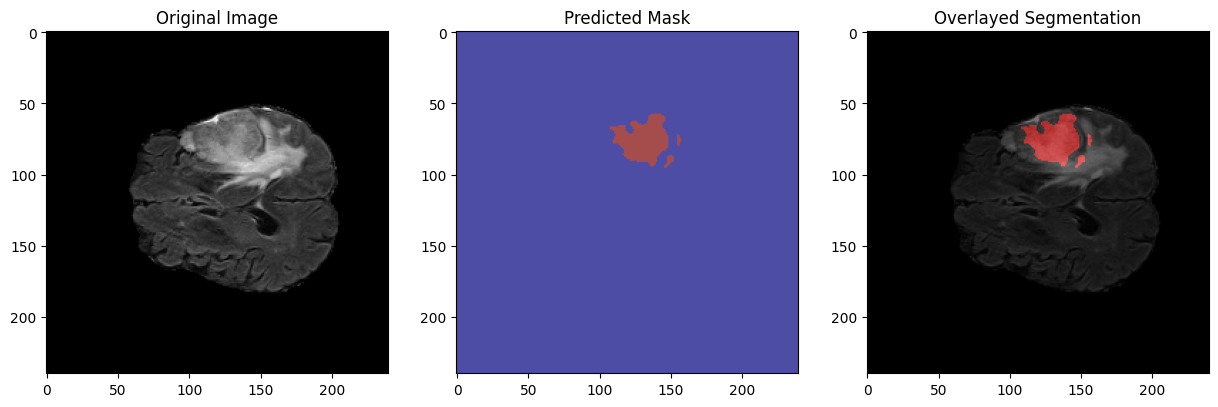

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

def predict_and_display_overlay(image, model):
    # Ensure the image is in the correct format: [1, Channels, Height, Width]
    img_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).to(device)  # Add batch dimension
    img_tensor = img_tensor.permute(0, 3, 1, 2)  # Change from [Height, Width, Channels] to [Batch, Channels, Height, Width]

    # Model prediction (for example SegNet)
    model.eval()  # Set model to evaluation mode
    with torch.no_grad():
        pred = model(img_tensor)  # Get prediction from model
        pred = torch.sigmoid(pred)  # Apply Sigmoid to get the probability map
        pred = (pred > 0.5).float()  # Convert probabilities to binary mask

    # Convert the tensor to numpy for visualization
    pred = pred.squeeze().cpu().numpy()  # Remove batch and channel dimensions, shape becomes [Height, Width]

    # Fix original image shape (take only the first channel if it has 4 channels)
    img = image[..., 0]  # Select the first channel to get a single grayscale image

    # Normalize the image if values are outside [0, 1]
    img = (img - img.min()) / (img.max() - img.min())  # Normalize between [0, 1]

    # Convert grayscale image to 3-channel for overlay
    img_rgb = np.stack([img] * 3, axis=-1)  # Convert [Height, Width] → [Height, Width, 3]

    # Overlay mask on the original image (red mask with alpha blending)
    overlay = np.zeros_like(img_rgb)  # Create an empty RGB image
    overlay[..., 0] = pred  # Apply mask to red channel (only tumors in red)

    # Blend original image with the mask
    alpha = 0.5  # Transparency level of mask
    blended = (1 - alpha) * img_rgb + alpha * overlay  # Merge with transparency

    # Display the original, mask, and overlayed images
    plt.figure(figsize=(15, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Image")

    # Predicted Mask
    plt.subplot(1, 3, 2)
    plt.imshow(pred, cmap='jet', alpha=0.7)  # Use jet colormap for visibility
    plt.title("Predicted Mask")

    # Overlayed Image
    plt.subplot(1, 3, 3)
    plt.imshow(blended)
    plt.title("Overlayed Segmentation")

    plt.show()

# Example usage:
img = X_val[0]  # Get an example image from your validation set
predict_and_display_overlay(img, segnet)  # Use SegNet or any model you like


# pyradiomics

In [7]:
!pip install pyradiomics SimpleITK

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.5/34.5 MB 13.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Discarding https://files.pythonhosted.org/packages/03/c1/20fc2c50ab1e3304da36d866042a1905a2b05a1431ece35448ab6b4578f2/pyradiomics-3.1.0.tar.gz (from https://pypi.org/simple/pyradiomics/): Requested pyradiomics from https://files.pythonhosted.org/packages/03/c1/20fc2c50ab1e3304da36d866042a1905a2b05a1431ece35448ab6b4578f2/pyradiomics-3.1.0.tar.gz has inconsistent version: expected '3.1.0', but metadata has '3.0.1a1'
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.5/34.5 MB 16.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.7/117.7 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 739.1/739.1 kB 48.7 MB/s eta 0:00:00
  Created wheel for pyradiomics: filename

In [18]:
import torch

# Save SegNet
torch.save(segnet.state_dict(), "/content/best_segnet_model (2).pth")

# Save UNet
torch.save(unet.state_dict(), "/content/best_u-net_model (1).pth")

print("✅ Models saved successfully!")


✅ Models saved successfully!


In [19]:
import numpy as np

def ensemble_predictions(images):
    segnet_preds = []
    unet_preds = []

    with torch.no_grad():
        for img in images:
            img_tensor = torch.tensor(img, dtype=torch.float32).unsqueeze(0).permute(0, 3, 1, 2).to(device)

            # Get predictions from SegNet and UNet
            segnet_pred = torch.sigmoid(segnet(img_tensor)).cpu().numpy()
            unet_pred = torch.sigmoid(unet(img_tensor)).cpu().numpy()

            segnet_preds.append(segnet_pred)
            unet_preds.append(unet_pred)

    # Average the predictions
    ensemble_preds = (np.array(segnet_preds) + np.array(unet_preds)) / 2

    # Convert probabilities to binary mask (threshold = 0.5)
    ensemble_preds = (ensemble_preds > 0.5).astype(np.uint8)

    return ensemble_preds

# Generate predictions
ensemble_val_preds = ensemble_predictions(X_val)

print("✅ Ensemble predictions generated successfully!")


✅ Ensemble predictions generated successfully!


In [91]:
import numpy as np
import SimpleITK as sitk
from radiomics import featureextractor

# Initialize feature extractor
extractor = featureextractor.RadiomicsFeatureExtractor()
extractor.enableAllFeatures()

def match_slices(image, mask):
    """
    Adjusts mask dimensions to match image dimensions by padding or slicing along slices (first axis).
    """
    img_slices = image.shape[0]
    mask_slices = mask.shape[0]

    if img_slices == mask_slices:
        return mask

    if mask_slices < img_slices:
        # Pad mask along slices (axis 0)
        pad = img_slices - mask_slices
        mask = np.pad(mask, ((0, pad), (0, 0), (0, 0)), mode='edge')
    else:
        # Slice mask to match image slices
        mask = mask[:img_slices, :, :]

    return mask

def extract_radiomics_features(image, mask):
    """
    Extract radiomics features with axis order handling.
    """
    # Convert to numpy arrays
    image = np.array(image)
    mask = np.array(mask)

    # Check and transpose axes if slices are not the first dimension
    if image.ndim == 3:
        # If slices are in the last dimension (common in some formats), transpose to (slices, height, width)
        if image.shape[-1] < image.shape[0]:  # Heuristic to detect slice position
            image = np.transpose(image, (2, 0, 1))
            mask = np.transpose(mask, (2, 0, 1))

    # Ensure 3D structure
    if image.ndim != 3 or mask.ndim != 3:
        print("⚠️ Image or mask has incorrect dimensions! Skipping.")
        return None

    # Match slices between image and mask
    mask = match_slices(image, mask)

    # Check for empty mask
    if np.max(mask) == 0:
        print("⚠️ Empty mask! Skipping.")
        return None

    # Convert to SimpleITK images (numpy array order: slices, height, width)
    image_sitk = sitk.GetImageFromArray(image.astype(np.float32))
    mask_sitk = sitk.GetImageFromArray(mask.astype(np.uint8))

    # Extract features
    try:
        features = extractor.execute(image_sitk, mask_sitk)
    except Exception as e:
        print(f"❌ Feature extraction failed: {e}")
        return None

    return {k: v for k, v in features.items() if isinstance(v, (int, float))}

# Process only the first 100 samples
features_list = [extract_radiomics_features(X_train[i], y_train_masks[i]) for i in range(min(200, len(X_train)))]

# Remove None values (skipped due to errors)
features_list = [f for f in features_list if f is not None]

# Convert to DataFrame
import pandas as pd
features_df = pd.DataFrame(features_list)

INFO:radiomics.featureextractor:No valid config parameter, using defaults: {'minimumROIDimensions': 2, 'minimumROISize': None, 'normalize': False, 'normalizeScale': 1, 'removeOutliers': None, 'resampledPixelSpacing': None, 'interpolator': 'sitkBSpline', 'preCrop': False, 'padDistance': 5, 'distances': [1], 'force2D': False, 'force2Ddimension': 0, 'resegmentRange': None, 'label': 1, 'additionalInfo': True}
INFO:radiomics.featureextractor:Enabled image types: {'Original': {}}
INFO:radiomics.featureextractor:Enabled features: {'firstorder': [], 'glcm': [], 'gldm': [], 'glrlm': [], 'glszm': [], 'ngtdm': [], 'shape': []}
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features 

⚠️ Empty mask! Skipping.


INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing ngtdm
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder
INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:

⚠️ Empty mask! Skipping.


INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing ngtdm
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder
INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:

...

INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder
INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing ngtdm
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.feat

⚠️ Empty mask! Skipping.


parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder
INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing ngtdm
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor

❌ Feature extraction failed: mask has too few dimensions (number of dimensions 1, minimum required 2)


INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.featureextractor:Calculating features for original image
INFO:radiomics.featureextractor:Computing firstorder
INFO:radiomics.featureextractor:Computing glcm
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated
INFO:radiomics.featureextractor:Computing gldm
INFO:radiomics.featureextractor:Computing glrlm
INFO:radiomics.featureextractor:Computing glszm
INFO:radiomics.featureextractor:Computing ngtdm
INFO:radiomics.featureextractor:Calculating features with label: 1
INFO:radiomics.featureextractor:Loading image and mask
INFO:radiomics.featureextractor:Computing shape
parameter force2D must be set to True to enable shape2D extraction
INFO:radiomics.featureextractor:Adding image type "Original" with custom settings: {}
INFO:radiomics.feat

In [95]:
features_df

,diagnostics_Image-original_Mean,diagnostics_Image-original_Minimum,diagnostics_Image-original_Maximum,diagnostics_Mask-original_VoxelNum,diagnostics_Mask-original_VolumeNum,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_MinorAxisLength,original_shape_VoxelVolume
0,7.618243e-09,-0.598047,8.437100,2938,5,0.433921,0.044224,3.492895,78.981341,34.271679,2938.0
1,2.207769e-09,-0.302244,12.686864,94,1,0.924868,0.000000,0.000000,13.032009,12.052893,94.0
2,1.429279e-08,-0.593152,9.721007,718,3,0.762361,0.057538,1.996035,34.690535,26.446725,718.0
3,-4.632940e-09,-0.527247,9.271222,101,1,0.585005,0.000000,0.000000,17.486663,10.229787,101.0
4,9.989330e-09,-0.524238,9.760783,77,1,0.312863,0.000000,0.000000,18.019356,5.637597,77.0
...,...,...,...,...,...,...,...,...,...,...,...
165,9.968093e-09,-0.639979,7.112155,3191,1,0.729911,0.032931,2.408181,73.127824,53.376803,3191.0
166,3.705922e-09,-0.596212,9.564301,85,1,0.508550,0.000000,0.000000,14.671597,7.461246,85.0
167,6.967747e-09,-0.562761,10.987257,1164,4,0.559300,0.035285,2.577519,73.047761,40.855639,1164.0
168,5.065871e-09,-0.624231,7.730535,1667,3,0.749848,0.050166,2.616511,52.157114,39.109916,1667.0


In [103]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd

# Ensure no NaNs in features
features_df = features_df.fillna(0)

# Convert to PyTorch tensors
X_tensor = torch.tensor(features_df.values, dtype=torch.float32)
y_tensor = torch.tensor(labels_subset, dtype=torch.long)

# Train/Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# **Define FCNN Model**
class TumorClassifier(nn.Module):
    def __init__(self, input_size):
        super(TumorClassifier, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)  # Binary classification (0 = No tumor, 1 = Tumor)
        )

    def forward(self, x):
        return self.fc(x)

# Model setup
input_size = features_df.shape[1]
model = TumorClassifier(input_size)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# **Training Loop**
epochs = 20
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} - Loss: {running_loss/len(train_loader):.4f}")

# **Evaluate Accuracy**
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = model(X_batch)
        _, predicted = torch.max(outputs, 1)
        total += y_batch.size(0)
        correct += (predicted == y_batch).sum().item()

accuracy = correct / total
print(f"✅ CNN Model Accuracy: {accuracy * 100:.2f}%")

# **Save Model**
torch.save(model.state_dict(), "radiomics_cnn_model.pth")
print("✅ CNN Model Trained & Saved Successfully! 🎯")


Epoch 1/20 - Loss: 0.1638
Epoch 2/20 - Loss: 0.1341
Epoch 3/20 - Loss: 0.1194
Epoch 4/20 - Loss: 0.1055
Epoch 5/20 - Loss: 0.0928
Epoch 6/20 - Loss: 0.0794
Epoch 7/20 - Loss: 0.0723
Epoch 8/20 - Loss: 0.0677
Epoch 9/20 - Loss: 0.0655
Epoch 10/20 - Loss: 0.0650
Epoch 11/20 - Loss: 0.0644
Epoch 12/20 - Loss: 0.0653
Epoch 13/20 - Loss: 0.0643
Epoch 14/20 - Loss: 0.0645
Epoch 15/20 - Loss: 0.0642
Epoch 16/20 - Loss: 0.0642
Epoch 17/20 - Loss: 0.0643
Epoch 18/20 - Loss: 0.0643
Epoch 19/20 - Loss: 0.0651
Epoch 20/20 - Loss: 0.0644
✅ CNN Model Accuracy: 100.00%
✅ CNN Model Trained & Saved Successfully! 🎯


In [45]:
import pandas as pd

# Assuming your DataFrame is named 'df'
features_df.to_csv('features_df.csv', index=False)

In [104]:
features_df.count()

,0
feat_0,200
feat_1,200
feat_2,200
feat_3,200
feat_4,200
feat_5,200
feat_6,200
feat_7,200
feat_8,200
feat_9,200


# GradCAM

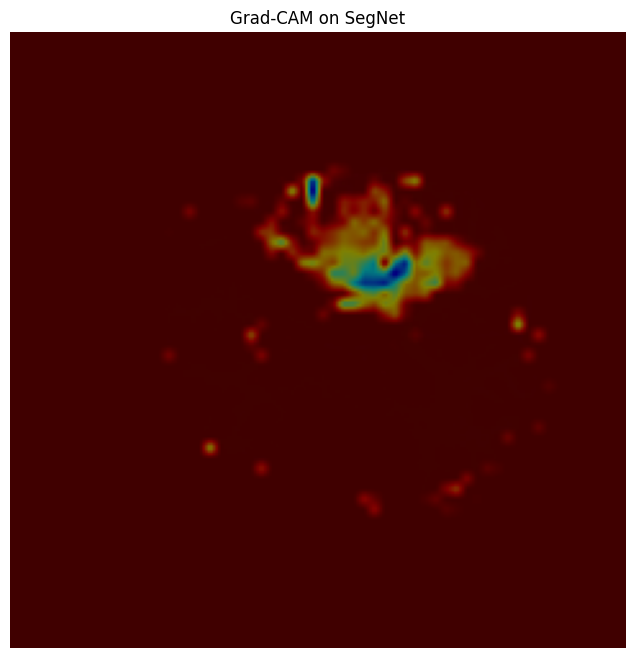

In [112]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

# **1. Hook to Capture Gradients**
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register hooks
        self.target_layer.register_forward_hook(self._save_activations)
        self.target_layer.register_backward_hook(self._save_gradients)

    def _save_activations(self, module, input, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_cam(self, img_tensor):
        """
        Generates Grad-CAM heatmap for a segmentation model.
        Since segmentation models output per-pixel predictions, we sum gradients.
        """
        self.model.eval()
        img_tensor.requires_grad = True
        img_tensor = img_tensor.to(device)

        # Forward pass
        output = self.model(img_tensor)

        # Take the mean across all output channels
        loss = output.mean()

        # Backward pass
        self.model.zero_grad()
        loss.backward()

        # Compute Grad-CAM
        gradients = self.gradients.cpu().numpy()
        activations = self.activations.cpu().numpy()

        # Compute weights: mean over spatial dimensions (H, W)
        weights = np.mean(gradients, axis=(2, 3), keepdims=True)

        # Weighted sum of activations
        cam = np.sum(weights * activations, axis=1)

        # Apply ReLU (remove negative values)
        cam = np.maximum(cam, 0)

        # Normalize
        cam = (cam - np.min(cam)) / (np.max(cam) + 1e-10)
        cam = np.squeeze(cam)

        return cam


# **2. Apply Grad-CAM to SegNet**
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt

def apply_gradcam(segnet_model, image, target_layer):
    """
    Apply Grad-CAM to SegNet for visualization.
    """
    gradcam = GradCAM(segnet_model, target_layer)

    # Convert image to tensor & preprocess
    img_tensor = torch.tensor(image, dtype=torch.float32).unsqueeze(0).permute(0, 3, 1, 2).to(device)

    # Generate Grad-CAM heatmap
    heatmap = gradcam.generate_cam(img_tensor)

    # Resize heatmap to original image size
    heatmap = cv2.resize(heatmap, (image.shape[1], image.shape[0]))

    # Normalize heatmap to 0-255 range
    heatmap = np.uint8(255 * heatmap)

    # Convert heatmap to 3-channel RGB
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    # **Ensure original image is in uint8 format**
    if image.max() <= 1:  # If image is in 0-1 range, scale to 0-255
        image = (image * 255).astype(np.uint8)
    else:
        image = image.astype(np.uint8)  # Convert float64 to uint8

    # **Ensure original image is 3-channel (RGB)**
    if image.shape[-1] == 4:  # Convert RGBA → RGB
        image = cv2.cvtColor(image, cv2.COLOR_RGBA2RGB)
    elif image.shape[-1] == 1:  # Convert single-channel → RGB
        image = np.repeat(image, 3, axis=-1)

    # **Ensure heatmap & image match in shape**
    if heatmap.shape[:2] != image.shape[:2]:
        heatmap = cv2.resize(heatmap, (image.shape[1], image.shape[0]))

    # **Blend Grad-CAM with the original image**
    blended = cv2.addWeighted(image, 0.5, heatmap.astype(np.uint8), 0.5, 0)

    return blended

# **3. Run Grad-CAM on a sample from X_val**
target_layer = segnet.encoder[-1]  # Change this if needed
sample_idx = 0  # Pick a sample
sample_image = X_val[sample_idx]

gradcam_output = apply_gradcam(segnet, sample_image, target_layer)

# Display the output
plt.figure(figsize=(8, 8))
plt.imshow(gradcam_output)
plt.axis("off")
plt.title("Grad-CAM on SegNet")
plt.show()


# DEBUG

In [ ]:
with torch.no_grad():
    sample_output = model(torch.rand(8, 4, 256, 256).to(device))
    print(f"Sample Output Range: {sample_output.min().item()} - {sample_output.max().item()}")


Sample Output Range: -2.6457741260528564 - 6.977452278137207


In [ ]:
print("Unique Mask Values:", np.unique(y_train_masks))


Unique Mask Values: [0. 1.]


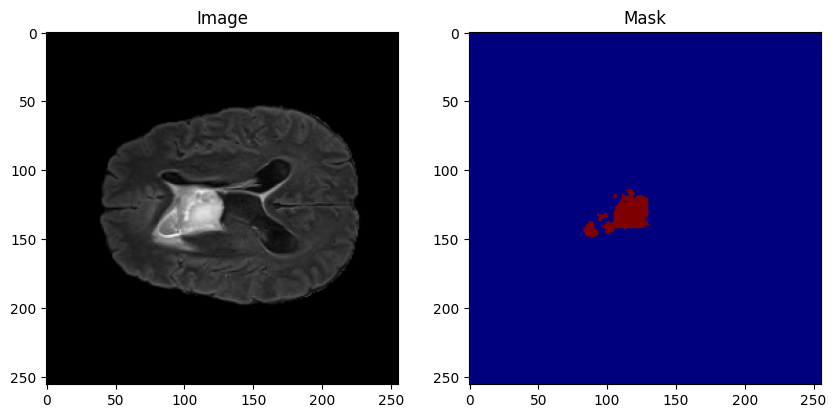

In [ ]:
import matplotlib.pyplot as plt

# Display images and masks from a batch
imgs, masks = next(iter(train_loader))
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imgs[0, 0].cpu().numpy(), cmap='gray')  # First channel of the image
plt.title("Image")

plt.subplot(1, 2, 2)
plt.imshow(masks[0, 0].cpu().numpy(), cmap='jet')  # First channel of the mask
plt.title("Mask")

plt.show()

